# Supplementary Fig S2 · Whole-tile search

The parts of the old Fig 3 (`_backup_2026-11-01/F3_whole_tile.ipynb`) that are not in the main Fig 2 (search time
and RDE / NNR per section are main Fig 2B, C; the memory-against-fidelity panel with PCA / PQ dropped 1 Nov: no
baselines), with the breadth sweep of R2.

* **A** time to compute the logarithms of a whole-tile query before the search: the whole-matrix logarithm (the
  whole-matrix scan) and the block logarithms in every niche (Spindle-naive and Spindle), median per seed, mean ± s.d.
* **B** the typical breast query: the exact d_B of every index tile (grey) and of the tiles Spindle returned; dashed,
  the distance of the c-th nearest index tile at c = 5 % of N.
* **C** RDE and NNR of Spindle against the search breadth g (default 0.25), every section, mean ± s.d. over seeds.

**Run first:** `R0_index_cache` → `R2_whole_tile` (`results/whole_tile/`) and `R4_timing`
(`results/timing/whole_tile.csv`). Writes `figures/figS2_whole_tile/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

import retrieval as rt
import style as ps
import whole_tile as wt

FIG = "figS2_whole_tile"
RES = ROOT / "results" / "whole_tile"
KEYS = ps.DATASET_ORDER
G = 0.25
SPINDLE, NAIVE, WHOLE = ps.TIER_COLORS["spindle"], ps.TIER_COLORS["naive"], ps.TIER_COLORS["whole"]
H1 = 62.0
TOP, BOTTOM = 6.0, 10.0              # mm above / below the axes in row 1
LEG_H = 9.0

_, timing = wt.timing_tables(pd.read_csv(ROOT / "results" / "timing" / "whole_tile.csv"))
timing = timing.set_index("key")
nx = pd.read_csv(RES / "nx.csv")
print(sorted(set(timing.tag) | set(nx.tag)))
timing[["qlog_whole_ms", "qlog_block_ms"]].round(2)


def ax_mm(fig, x, y, w, h):
    """Axes at (x, y) mm from the panel's bottom-left corner, w x h mm."""
    W, H = ps.size_mm(fig)
    return fig.add_axes([x / W, y / H, w / W, h / H])


def rows_axis(ax, labels):
    ax.set_ylim(len(KEYS) - 0.5, -0.5)
    ax.set_yticks(range(len(KEYS)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in KEYS] if labels else [])
    ax.tick_params(axis="y", length=0)

['method-v2']


## A · Time to compute the logarithms of the query

figures/figS2_whole_tile/panels/A.pdf/.png: 54 x 62 mm, 0.0 / 0.3 MB


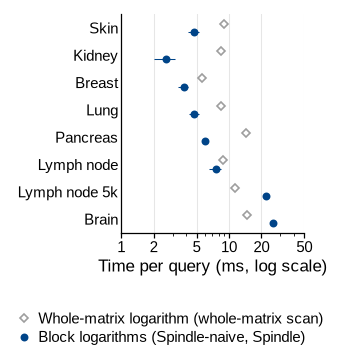

In [2]:
QLOG_HANDLES = [Line2D([], [], ls="", marker="D", ms=2.6, mfc="white", mec=WHOLE, mew=0.8,
                       label="Whole-matrix logarithm (whole-matrix scan)"),
                Line2D([], [], ls="", marker="o", ms=2.8, color=NAIVE, label="Block logarithms (Spindle-naive, Spindle)")]


def panel_a(fig):
    ax = ps.axes(fig, left=20.0, right=3.0, bottom=BOTTOM + LEG_H, top=TOP)
    for i, k in enumerate(KEYS):
        r = timing.loc[k]
        ax.errorbar(r.qlog_whole_ms, i - 0.15, xerr=r.qlog_whole_ms_sd, fmt="D", ms=2.6, mfc="white", mec=WHOLE,
                    mew=0.8, ecolor=WHOLE, elinewidth=0.5, zorder=3)
        ax.errorbar(r.qlog_block_ms, i + 0.15, xerr=r.qlog_block_ms_sd, fmt="o", ms=2.8, color=NAIVE, elinewidth=0.5,
                    zorder=3)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0, 2.0, 5.0))
    ps.log_grid(ax, "x")
    ax.set_xlim(1, 50)
    rows_axis(ax, True)
    ax.set_xlabel("Time per query (ms, log scale)")
    fig.legend(handles=QLOG_HANDLES, ncol=1, loc="lower left", bbox_to_anchor=(2.0 / ps.size_mm(fig)[0], 0.0))


fig = ps.panel(54, H1); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · The typical breast query

breast typical query: N = 1840, returned 484, c = 92, d_c = 0.749
figures/figS2_whole_tile/panels/B.pdf/.png: 54 x 62 mm, 0.0 / 0.2 MB


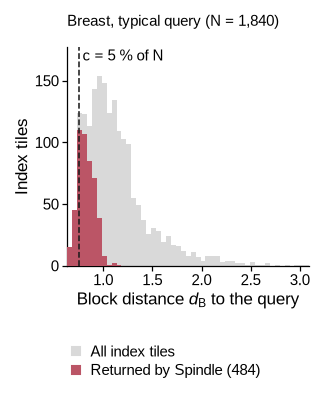

In [3]:
def panel_b(fig):
    z = np.load(RES / "band" / "breast_cancer.npz")
    d, found = z["d"], z["found"]
    c = rt.c5(len(d))
    d_c = np.sort(d)[c - 1]
    print(f"breast typical query: N = {len(d)}, returned {len(found)}, c = {c}, d_c = {d_c:.3f}")
    ax = ps.axes(fig, left=11.0, right=2.0, bottom=BOTTOM + LEG_H, top=TOP)
    bins = np.linspace(d.min(), np.quantile(d, 0.995), 50)
    n_all, _, _ = ax.hist(d, bins=bins, color=ps.LIGHT, lw=0, zorder=2)
    ax.hist(d[found], bins=bins, color=SPINDLE, lw=0, zorder=3)
    ax.axvline(d_c, ls="--", lw=0.75, color=ps.INK, zorder=4)
    ax.text(d_c, 0.99, " c = 5 % of N", transform=ax.get_xaxis_transform(), ha="left", va="top", fontsize=ps.TICK_PT)
    ax.set_ylim(0, 1.15 * n_all.max())
    ax.set_xlabel(r"Block distance $d_{\mathcal{B}}$ to the query")
    ax.set_ylabel("Index tiles")
    ax.set_xlim(bins[0], bins[-1])
    W, H = ps.size_mm(fig)
    fig.text(11.0 / W, 1 - 0.5 / H, f"Breast, typical query (N = {len(d):,})", va="top", fontsize=ps.TICK_PT)
    handles = [Line2D([], [], ls="", marker="s", ms=3.5, color=ps.LIGHT, label="All index tiles"),
               Line2D([], [], ls="", marker="s", ms=3.5, color=SPINDLE, label=f"Returned by Spindle ({len(found)})")]
    fig.legend(handles=handles, ncol=1, loc="lower left", bbox_to_anchor=(11.0 / W, 0.0))


fig = ps.panel(54, H1); panel_b(fig); ps.save_panel(fig, FIG, "B")

## C · RDE and NNR against the search breadth g

figures/figS2_whole_tile/panels/C.pdf/.png: 72 x 62 mm, 0.0 / 0.5 MB


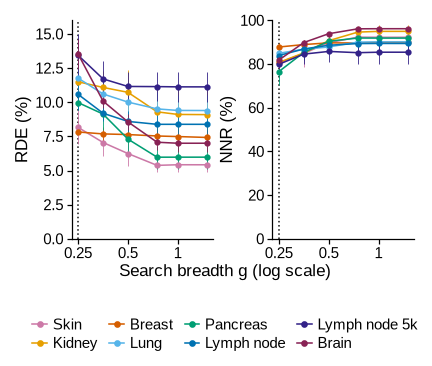

In [4]:
GS = sorted(nx.g.unique())
G_HANDLES = [Line2D([], [], marker="o", ms=2.2, lw=0.75, color=ps.DATASET_COLORS[k], label=ps.DATASET_LABELS[k])
             for k in KEYS]


def panel_c(fig):
    W, H = ps.size_mm(fig)
    w = (W - 4.0) / 2
    for j, (col, ylabel, ylim) in enumerate((("NX5", "RDE (%)", (0, 16)), ("overlap5", "NNR (%)", (0, 100)))):
        ax = ax_mm(fig, 10.0 + j * w, BOTTOM + LEG_H, w - 10.0, H - BOTTOM - LEG_H - TOP)
        for k in KEYS:
            s = nx[nx.key == k].sort_values("g")
            ax.errorbar(s.g, 100 * s[col], yerr=100 * s[f"{col}_sd"], fmt="-o", ms=2.0, lw=0.75,
                        color=ps.DATASET_COLORS[k], elinewidth=0.4, zorder=3)
        ax.axvline(G, ls=":", lw=0.75, color=ps.INK, zorder=1)
        ax.set_xscale("log", base=2)
        ax.set_xticks([0.25, 0.5, 1.0], ["0.25", "0.5", "1"])
        ax.minorticks_off()
        ax.set_ylim(*ylim)
        ax.set_ylabel(ylabel)
    fig.text(0.5, (BOTTOM + LEG_H - 7.0) / H, "Search breadth g (log scale)", ha="center", va="bottom")
    fig.legend(handles=G_HANDLES, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0.0), columnspacing=0.8,
               handlelength=1.0)


fig = ps.panel(72, H1); panel_c(fig); ps.save_panel(fig, FIG, "C")

## Full figure

breast typical query: N = 1840, returned 484, c = 92, d_c = 0.749
figures/figS2_whole_tile/figS2_whole_tile.pdf/.png: 180 x 62 mm, 0.0 / 1.0 MB


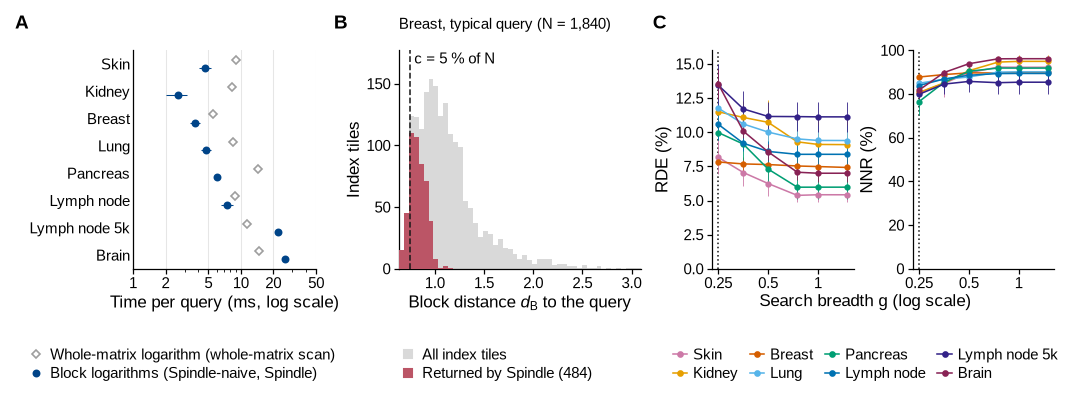

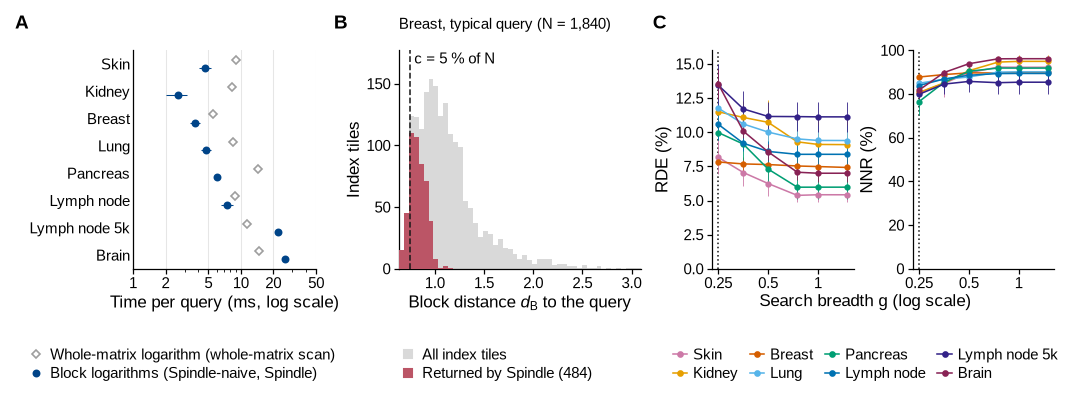

In [5]:
page = ps.page(180, H1)
panel_a(ps.place(page, "A", 0, 0, 54, H1))
panel_b(ps.place(page, "B", 54, 0, 54, H1))
panel_c(ps.place(page, "C", 108, 0, 72, H1))
ps.save_figure(page, FIG)
page